[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C06/E06-1_Diagnostic_Vibratoire_CORRIGE.ipynb)

# Diagnostic des défauts d'une machine tournante : estimer la probabilité d'un défaut

## Le contexte

Sur un banc de contrôle, chaque machine tournante est instrumentée et son spectre de vibration est résumé par dix indicateurs : le niveau global, les amplitudes à la moitié, à une fois et à deux fois la fréquence de rotation, l'amplitude haute fréquence des roulements, l'amplitude à la fréquence d'engrènement, les bandes latérales, le bruit large bande, le kurtosis et le facteur de crête. Chaque machine est dans l'un de six états : saine, avec un jeu d'accouplement, déséquilibrée, avec un défaut de denture, un défaut de roulement ou un désalignement. Le service maintenance voudrait attribuer une cause probable à partir des seuls indicateurs, sans démonter la machine.

La grandeur à prédire est un état parmi six : c'est un problème de classification multiclasse.

Défi : prédire `Defaut` et obtenir un F-score macro supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est une régression logistique sur les dix indicateurs mis à l'échelle ; il atteint un F-score macro de 0,905 : à vous de faire mieux. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Diagnostic_Vibratoire.xlsx`, dans le dossier `donnees` du dépôt : 2 400 machines, 12 colonnes. Une ligne est une machine.

| Colonne | Signification | Unité |
|---|---|---|
| `Piece_ID` | identifiant de la machine, écarté à l'étape 2 | sans unité |
| `Vib_RMS_globale_mms` | niveau vibratoire global, valeur efficace du signal entier | mm/s |
| `Amp_05x_tr_mms`, `Amp_1x_tr_mms`, `Amp_2x_tr_mms` | valeurs efficaces des raies à 0,5, 1 et 2 fois la fréquence de rotation | mm/s |
| `Amp_HF_roulement_mms` | valeur efficace haute fréquence, propre aux roulements | mm/s |
| `Amp_freq_maillage_mms`, `Amp_sidebands_mms` | valeurs efficaces de la raie d'engrènement et des bandes latérales | mm/s |
| `Bruit_large_bande_mms` | bruit large bande, valeur efficace | mm/s |
| `Kurtosis`, `Crest_factor` | aplatissement et facteur de crête du signal | sans dimension |
| `Defaut` | cible : état de la machine, parmi six | catégorie |

Origine : jeu construit, spectres de machines tournantes simulés pour six états. Il enseigne une méthode, et aucune conclusion de maintenance n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la répartition des six états avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Diagnostic_Vibratoire.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Diagnostic_Vibratoire.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "Defaut"
print("dimensions :", df.shape)
print("cases vides au total :", int(df.isna().sum().sum()))
print(df[cible].value_counts().to_string())
print("identifiants distincts :", df["Piece_ID"].nunique())
df.head(3)

dimensions : (2400, 12)
cases vides au total : 0
Defaut
Sain                501
Déséquilibrage      404
Désalignement       400
Jeu accouplement    370
Défaut roulement    365
Défaut denture      360
identifiants distincts : 2400


,Piece_ID,Vib_RMS_globale_mms,Amp_05x_tr_mms,Amp_1x_tr_mms,Amp_2x_tr_mms,Amp_HF_roulement_mms,Amp_freq_maillage_mms,Amp_sidebands_mms,Bruit_large_bande_mms,Kurtosis,Crest_factor,Defaut
0,1001,3.4940,0.102,0.379,0.195,3.225,0.341,0.177,1.199,41.95,8.33,Défaut roulement
1,1002,1.6467,0.119,1.377,0.243,0.238,0.404,0.194,0.684,2.43,2.74,Déséquilibrage
2,1003,1.1074,0.078,0.459,0.222,0.286,0.368,0.171,0.754,2.77,3.37,Désalignement


Lecture du résultat : 2 400 machines, 12 colonnes, aucune case vide. Les six états sont présents en proportions voisines, avec un peu plus de machines saines (501) que de machines de chaque état de défaut (de 360 à 404). `Piece_ID` est un identifiant propre à chaque machine : il ne décrit pas son état, il sera écarté.

### Étape 2 : mettre le test de côté

Un quart des machines est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. Le tirage est stratifié, pour que chaque état soit représenté dans les deux bases dans la même proportion. L'identifiant est écarté.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[cible, "Piece_ID"])
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=GRAINE, stratify=y)
print("apprentissage :", len(X_train), "machines")
print("test :", len(X_test), "machines")

apprentissage : 1800 machines
test : 600 machines


### Étape 3 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : une régression logistique, qui estime une probabilité par état et retient l'état le plus probable. Les dix indicateurs, d'ordres de grandeur différents, sont mis à l'échelle sur l'apprentissage seul, dans le même pipeline. Il apprend sur `X_train`.

In [3]:
# Solution :
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

### Étape 4 : mesurer sur la base de test

Le modèle prédit les machines qu'il n'a jamais vues. On lit l'exactitude (part de réponses justes), le F-score macro (moyenne des F-scores des six états, qui compte chaque état pour autant) et le F-score de chaque état. Un témoin sans apprentissage, qui répond toujours l'état le plus fréquent, donne le point de comparaison le plus bas.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

y_pred = modele.predict(X_test)
score_depart = f1_score(y_test, y_pred, average="macro")
temoin = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
score_temoin = f1_score(y_test, temoin.predict(X_test), average="macro")
print(f"F-score macro : {score_depart:.3f}")
print(f"exactitude : {accuracy_score(y_test, y_pred):.3f}")
print(f"F-score macro du témoin (toujours l'état le plus fréquent) : {score_temoin:.3f}")
classes = list(modele.classes_)
f_etats = pd.Series(f1_score(y_test, y_pred, average=None, labels=classes), index=classes)
print(f_etats.round(3).to_string())

F-score macro : 0.905
exactitude : 0.893
F-score macro du témoin (toujours l'état le plus fréquent) : 0.057
Défaut denture      0.972
Défaut roulement    0.989
Désalignement       0.876
Déséquilibrage      0.884
Jeu accouplement    0.906
Sain                0.801


Lecture du résultat : le F-score macro est de 0,905 pour une exactitude de 0,893, très au-dessus du témoin (0,057), qui n'est juste que pour l'état le plus fréquent. Le F-score le plus bas est celui de l'état `Sain` (0,801), le plus haut celui de l'état `Défaut roulement` (0,989) : un défaut naissant, encore proche de l'état sain, est la cause d'erreur la plus fréquente. C'est ce chiffre, mesuré sur des machines que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : lire les confusions, puis changer ce que le modèle voit

Le modèle de départ de l'étape 3 reste le score de référence du défi. Les trois cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première lit les confusions du modèle de départ sur l'apprentissage, par validation croisée : elles disent quels états il mélange. La deuxième compare par validation croisée des variantes de la régression logistique, un modèle de plus proches voisins et un modèle probabiliste de famille différente, le Bayes naïf gaussien. La troisième mesure le modèle retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

confusion la plus fréquente : réel Déséquilibrage, prédit Sain, 79 machines


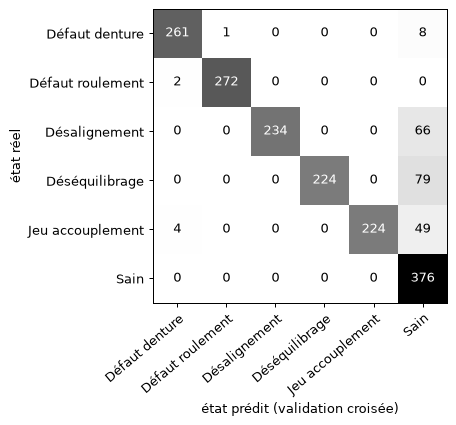

In [5]:
# Solution :
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
pred_cv = cross_val_predict(modele, X_train, y_train, cv=plis)
matrice = pd.DataFrame(confusion_matrix(y_train, pred_cv, labels=classes), index=classes, columns=classes)
confusions = matrice.where(~np.eye(len(classes), dtype=bool)).stack()
pire = confusions.idxmax()
print(f"confusion la plus fréquente : réel {pire[0]}, prédit {pire[1]}, {int(confusions.max())} machines")

fig, ax = plt.subplots(figsize=(5.4, 4.8))
ConfusionMatrixDisplay.from_predictions(y_train, pred_cv, labels=classes, cmap="Greys", colorbar=False, ax=ax)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
ax.set_xlabel("état prédit (validation croisée)")
ax.set_ylabel("état réel")
plt.tight_layout()
plt.show()
# Fin de la solution

In [6]:
# Solution :
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures

en_logarithmes = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
candidats = {
    "départ : logistique à l'échelle": modele,
    "logistique, pénalité plus faible (C=100)": make_pipeline(
        StandardScaler(), LogisticRegression(C=100, max_iter=5000)),
    "logistique sur logarithmes et produits deux à deux": make_pipeline(
        en_logarithmes, StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
        LogisticRegression(max_iter=5000)),
    "plus proches voisins à l'échelle": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Bayes naïf gaussien": GaussianNB()}
notes_cv = {}
for nom, pipeline in candidats.items():
    notes = cross_val_score(pipeline, X_train, y_train, cv=plis, scoring="f1_macro")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : F-score macro {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
# Fin de la solution

départ : logistique à l'échelle : F-score macro 0.896 +/- 0.013 sur 5 plis
logistique, pénalité plus faible (C=100) : F-score macro 0.950 +/- 0.014 sur 5 plis
logistique sur logarithmes et produits deux à deux : F-score macro 0.949 +/- 0.017 sur 5 plis
plus proches voisins à l'échelle : F-score macro 0.928 +/- 0.016 sur 5 plis
Bayes naïf gaussien : F-score macro 0.819 +/- 0.010 sur 5 plis
modèle retenu par la validation croisée : logistique, pénalité plus faible (C=100)


In [7]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
f1_retenu = f1_score(y_test, retenu.predict(X_test), average="macro")
print(f"{nom_retenu}, mesuré une fois sur le test : F-score macro {f1_retenu:.3f}")
print(f"gain sur le modèle de départ : {f1_retenu - score_depart:+.3f}")
print("lecture : les amplitudes ont une queue lourde et des dispersions très inégales d'un état à l'autre ;")
print("une pénalité plus faible ou une autre présentation des indicateurs les séparent mieux.")
# Fin de la solution

logistique, pénalité plus faible (C=100), mesuré une fois sur le test : F-score macro 0.958
gain sur le modèle de départ : +0.053
lecture : les amplitudes ont une queue lourde et des dispersions très inégales d'un état à l'autre ;
une pénalité plus faible ou une autre présentation des indicateurs les séparent mieux.


## Le score de référence

Le score publié est le F-score macro du modèle de départ de l'étape 3 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [8]:
import hashlib

score = f1_score(y_test, modele.predict(X_test), average="macro")
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE f1_macro = %.3f" % score)

EMPREINTE_TEST = 0753c2edf1506f042648788eb7f733a298be52161603ddd33af346e14ee49ee9
SCORE_REFERENCE f1_macro = 0.905


## Synthèse

1. Une régression logistique multiclasse estime une probabilité par état et retient la plus forte ; ses frontières sont planes dans l'espace des indicateurs.
2. Un témoin qui répond toujours l'état le plus fréquent donne un plancher de comparaison : le F-score macro, qui compte chaque état pour autant, le met très bas.
3. Les confusions se lisent sur l'apprentissage, par validation croisée : elles désignent les états que le modèle mélange, sans toucher au test.
4. Une variante de la même famille, ici des logarithmes et des produits d'indicateurs, ou un modèle d'une autre famille, peut mieux coller à des amplitudes à queue lourde ; on le sait par la validation croisée, pas par le test.
5. Le choix du modèle se fait sur l'apprentissage ; le test ne sert qu'une fois, au modèle retenu.